In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('emails.csv')

print(df.head())
print(df.shape)
print(df.info())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
(5172, 3002)
<class 'pandas.core.frame.DataFrame'>
RangeIndex:

In [2]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nColumn Names:")
print(df.columns)

print("\nTarget Distribution:")
print(df['Prediction'].value_counts())

Missing Values:
0

Duplicate Rows:
0

Column Names:
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)

Target Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [3]:
X = df.drop(['Email No.', 'Prediction'], axis=1)
y = df['Prediction']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5172, 3000)
Target Shape: (5172,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [6]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Model Training Completed")

KNN Model Training Completed


In [7]:
svm = SVC(kernel='linear')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Model Training Completed")

SVM Model Training Completed


KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       739
           1       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035

KNN Accuracy: 84.54106280193237 %


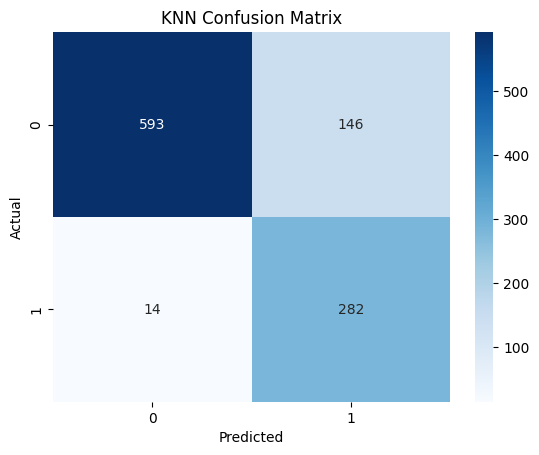

In [8]:
print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn) * 100, "%")

cm_knn = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       739
           1       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035

KNN Accuracy: 84.54106280193237 %


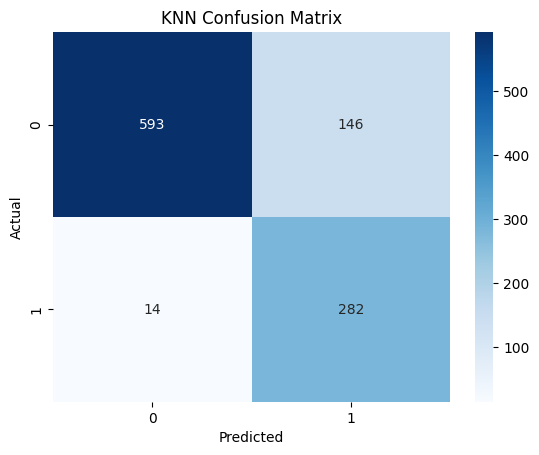

In [9]:
print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn) * 100, "%")

cm_knn = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [10]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn) * 100,
        accuracy_score(y_test, y_pred_svm) * 100
    ]
})

print(results)

  Model   Accuracy
0   KNN  84.541063
1   SVM  94.685990


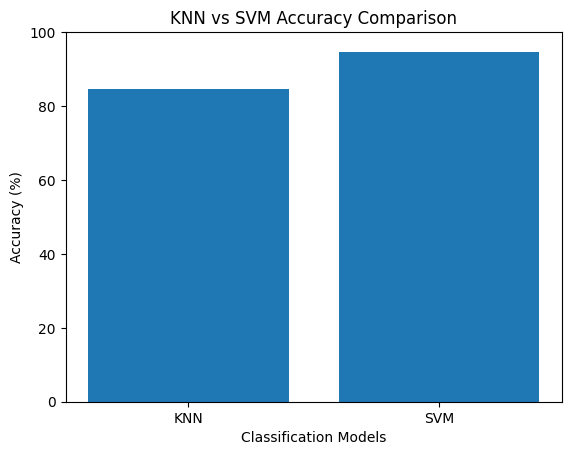

In [11]:
plt.bar(results['Model'], results['Accuracy'])
plt.title("KNN vs SVM Accuracy Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()